# 一个格子世界里的强化学习进化史（学生版）

本实验用一个 5×5 的格子世界，走完强化学习（Reinforcement Learning，RL）
从经典方法到前沿范式的完整链条：

| 部分 | 我们知道什么 | 方法 |
|---|---|---|
| Part 1 | 已知模型（转移概率和奖励都已知） | 值迭代 |
| Part 2 | 未知模型，但已知奖励 | Q-learning |
| Part 3 | 未知奖励，只有偏好数据 | Mini-RLHF |
| Part 4 | 奖励可以被程序化验证 | Verifiable Reward |

四个部分使用同一个环境。后面的部分会直接复用前面的代码。

**填写说明**

- 需要补全的代码用 `TODO` 标出，共 7 处；思考题共 4 组。
- 每处 `TODO` 上方都有提示，补全后运行该单元格和后续单元格检查。
- 环境类、绘图函数和数据收集函数都已提供，不需要修改。

运行环境：Python 3.10 以上，只需要 numpy 和 matplotlib。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

rng = np.random.default_rng(42)
plt.rcParams['figure.dpi'] = 100

## 第 0 部分：认识环境

我们使用的环境是一个 5×5 的格子世界，规则如下：

- 智能体从左上角的 S（起点）出发，目标是到达 G（终点）。
- 每步可以向上、下、左、右移动一格；撞墙或撞到边界则停在原地。
- 灰色的格子是墙，无法通过。
- 红色的格子是陷阱（Trap）。踩入陷阱不会结束回合，但会付出很大代价。
- 每走一步获得奖励 -0.1；踩入陷阱获得奖励 -10；到达终点获得奖励 +10，回合结束。

请注意地图的结构：从 S 到 G 有两条路。

- 穿过陷阱的近路，共 6 步。
- 绕开陷阱的远路，共 10 步。

绕远路多花的代价是 4 × 0.1 = 0.4，远小于踩陷阱的代价 10。
因此最优策略应该绕远路。

In [2]:
class GridWorld:
    """5x5 格子世界。接口仿照 Gymnasium：reset() 返回状态，step(a) 返回
    (下一状态, 奖励, 回合结束, 步数超限, 附加信息)。状态用 0～24 的整数表示。"""

    ROWS, COLS = 5, 5
    START = (0, 0)
    GOAL = (2, 4)
    TRAP = (2, 2)
    WALLS = {(0, 2), (1, 2), (3, 2)}
    R_STEP, R_TRAP, R_GOAL = -0.1, -10.0, 10.0
    ACTIONS = [(-1, 0), (0, 1), (1, 0), (0, -1)]  # 上、右、下、左
    ACTION_SYMBOLS = ['↑', '→', '↓', '←']

    def __init__(self, slip=0.0, max_steps=50, seed=0):
        # slip 是打滑概率：以 slip 的概率执行一个随机动作，用于思考题的随机环境
        self.slip = slip
        self.max_steps = max_steps
        import numpy as np
        self.rng = np.random.default_rng(seed)
        self.n_states = self.ROWS * self.COLS
        self.n_actions = 4
        self.P = self._build_P()  # 转移表：P[s][a] = [(概率, 下一状态, 奖励, 是否结束), ...]
        self.reset()

    @staticmethod
    def to_pos(s):
        return divmod(s, GridWorld.COLS)

    @staticmethod
    def to_state(pos):
        return pos[0] * GridWorld.COLS + pos[1]

    def _move(self, pos, a):
        if pos == self.GOAL:
            return pos
        dr, dc = self.ACTIONS[a]
        r, c = pos[0] + dr, pos[1] + dc
        if r < 0 or r >= self.ROWS or c < 0 or c >= self.COLS or (r, c) in self.WALLS:
            return pos
        return (r, c)

    def _outcome(self, pos, a):
        nxt = self._move(pos, a)
        if nxt == self.GOAL:
            return nxt, self.R_GOAL, True
        if nxt == self.TRAP:
            return nxt, self.R_TRAP, False
        return nxt, self.R_STEP, False

    def _build_P(self):
        P = {}
        for s in range(self.n_states):
            pos = self.to_pos(s)
            P[s] = {}
            for a in range(self.n_actions):
                if self.slip > 0:
                    merged = {}
                    for a2 in range(self.n_actions):
                        prob = (1 - self.slip) if a2 == a else 0.0
                        prob += self.slip / self.n_actions
                        nxt, r, done = self._outcome(pos, a2)
                        key = (self.to_state(nxt), r, done)
                        merged[key] = merged.get(key, 0.0) + prob
                    P[s][a] = [(p, ns, r, d) for (ns, r, d), p in merged.items()]
                else:
                    nxt, r, done = self._outcome(pos, a)
                    P[s][a] = [(1.0, self.to_state(nxt), r, done)]
        return P

    def reset(self):
        self.pos = self.START
        self.steps = 0
        return self.to_state(self.pos)

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = int(self.rng.integers(self.n_actions))
        nxt, r, done = self._outcome(self.pos, a)
        self.pos = nxt
        self.steps += 1
        truncated = self.steps >= self.max_steps and not done
        return self.to_state(nxt), r, done, truncated, {}

下面的单元格定义本实验用到的所有绘图函数。你不需要修改它们，直接运行即可。

In [3]:
def draw_world(ax, title=''):
    """画出格子世界的底图：墙、陷阱、起点和终点。"""
    color_map = {}
    for w in GridWorld.WALLS:
        color_map[w] = '#555555'
    color_map[GridWorld.TRAP] = '#f2b8b8'
    color_map[GridWorld.GOAL] = '#b8e6b8'
    color_map[GridWorld.START] = '#b8d4f0'
    for r in range(GridWorld.ROWS):
        for c in range(GridWorld.COLS):
            face = color_map.get((r, c), 'white')
            ax.add_patch(Rectangle((c, GridWorld.ROWS - 1 - r), 1, 1,
                                   facecolor=face, edgecolor='#999999'))
    def center(pos):
        return pos[1] + 0.5, GridWorld.ROWS - 1 - pos[0] + 0.5
    ax.text(*center(GridWorld.START), 'S', ha='center', va='center', fontsize=14, weight='bold')
    ax.text(*center(GridWorld.GOAL), 'G', ha='center', va='center', fontsize=14, weight='bold')
    ax.text(*center(GridWorld.TRAP), 'T', ha='center', va='center', fontsize=14, weight='bold')
    ax.set_xlim(0, GridWorld.COLS)
    ax.set_ylim(0, GridWorld.ROWS)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)


def plot_policy(policy, title='Policy'):
    """用箭头画出每个状态的策略。policy[s] 是动作编号 0～3。"""
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    draw_world(ax, title)
    for s in range(GridWorld.ROWS * GridWorld.COLS):
        pos = GridWorld.to_pos(s)
        if pos in GridWorld.WALLS or pos == GridWorld.GOAL:
            continue
        dr, dc = GridWorld.ACTIONS[policy[s]]
        x, y = pos[1] + 0.5, GridWorld.ROWS - 1 - pos[0] + 0.5
        ax.arrow(x, y, dc * 0.3, -dr * 0.3, head_width=0.12,
                 head_length=0.1, fc='#1f77b4', ec='#1f77b4')
    plt.show()


def plot_values(V, title='State values'):
    """画出每个状态的价值热力图。"""
    grid = np.full((GridWorld.ROWS, GridWorld.COLS), np.nan)
    for s in range(GridWorld.ROWS * GridWorld.COLS):
        pos = GridWorld.to_pos(s)
        if pos not in GridWorld.WALLS:
            grid[pos] = V[s]
    fig, ax = plt.subplots(figsize=(5, 4.5))
    masked = np.ma.masked_invalid(grid)
    im = ax.imshow(masked, cmap='viridis')
    for r in range(GridWorld.ROWS):
        for c in range(GridWorld.COLS):
            if not np.isnan(grid[r, c]):
                ax.text(c, r, f'{grid[r, c]:.1f}', ha='center', va='center',
                        fontsize=9, color='white')
    for w in GridWorld.WALLS:
        ax.add_patch(Rectangle((w[1] - 0.5, w[0] - 0.5), 1, 1, facecolor='#555555'))
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.show()


def plot_trajectory(traj, title='Trajectory'):
    """在地图上画出一条轨迹。traj 是状态编号的列表。"""
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    draw_world(ax, title)
    xs = [GridWorld.to_pos(s)[1] + 0.5 for s in traj]
    ys = [GridWorld.ROWS - 1 - GridWorld.to_pos(s)[0] + 0.5 for s in traj]
    ax.plot(xs, ys, 'o-', color='#d62728', lw=2, markersize=6)
    plt.show()


def plot_returns(returns, title='Learning curve', window=100):
    """画出学习曲线：浅色是每个回合的回报，深色是滑动平均。"""
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(returns, alpha=0.25, color='#1f77b4', label='Episode return')
    if len(returns) >= window:
        avg = np.convolve(returns, np.ones(window) / window, mode='valid')
        ax.plot(np.arange(window - 1, len(returns)), avg,
                color='#d62728', lw=2, label=f'Moving average ({window})')
    ax.set_xlabel('Episode')
    ax.set_ylabel('Return')
    ax.set_title(title)
    ax.legend()
    plt.show()

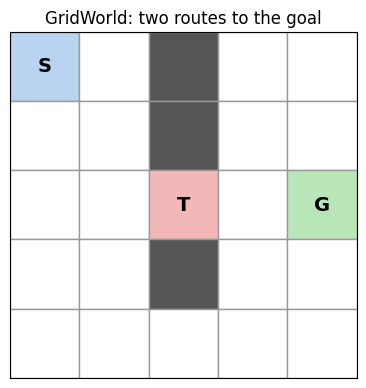

P[start][right] = [(1.0, 1, -0.1, False)]
step -> state=(1, 0), reward=-0.1, done=False
step -> state=(1, 1), reward=-0.1, done=False
step -> state=(1, 1), reward=-0.1, done=False


In [4]:
env = GridWorld(seed=0)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_world(ax, 'GridWorld: two routes to the goal')
plt.show()

# 转移表的一个例子：在起点向右走，只有一种结果（确定性环境）
s_start = GridWorld.to_state(GridWorld.START)
print('P[start][right] =', env.P[s_start][1])

# 手动与环境交互几步
s = env.reset()
for a in [2, 1, 1]:  # 下、右、右
    s, r, done, truncated, _ = env.step(a)
    print(f'step -> state={GridWorld.to_pos(s)}, reward={r}, done={done}')

## Part 1：值迭代（已知模型）

**知识回顾**

一个状态值多少钱？等于现在能得到多少，加上以后大概还能得到多少。
用一句话说：当前价值 = 当前奖励 + 折扣后的未来价值。

当转移概率 P 和奖励 R 都已知时，最优价值函数满足 Bellman 最优方程：

$$V^*(s) = \max_a \sum_{s'} P(s'|s,a)\left[R(s,a,s') + \gamma V^*(s')\right]$$

值迭代（Value Iteration）的做法很直接：从 V = 0 开始，反复套用上面的等式右边，
直到 V 不再变化。

**你的任务**

1. 补全 `value_iteration` 中的更新式。
2. 补全 `extract_policy`，从 V 中提取最优策略。

提示：对每个状态 s 和动作 a，先算出
$Q(s,a) = \sum_{s'} P(s'|s,a)[R + \gamma V(s')]$，
再对所有动作取最大。环境的转移表是 `env.P[s][a]`，
其中每一项是 `(概率, 下一状态, 奖励, 是否结束)`；回合结束时未来价值按 0 计。

In [5]:
def value_iteration(env, gamma=0.9, tol=1e-10, max_iter=10000):
    import numpy as np
    V = np.zeros(env.n_states)
    for _ in range(max_iter):
        delta = 0.0
        for s in range(env.n_states):
            q_values = []
            for a in range(env.n_actions):
                # TODO 1：计算 Q(s,a) = Σ P(s'|s,a) · [R + γ·V(s')]。
                # 提示：env.P[s][a] 是 (概率, 下一状态, 奖励, 是否结束) 的列表；
                # 回合结束时未来价值按 0 计。
                # 我的思路： 
                # q = 0
                # for p1, s1, r1, e1 in env.P[s][a]:
                #   if e1 == True:
                #       q += p1 * r1;
                #   else:
                #       q += p1 * (r1 + gamma * V[s1])
                q = 0
                for p1, s1, r1, e1 in env.P[s][a]:
                    if e1 == True:
                        q += p1 * r1;
                    else:
                        q += p1 * (r1 + gamma * V[s1])
                q_values.append(q)
            # TODO 2：对所有动作取最大，得到 v_new。
            # 我的思路： v_new = max(q_values)
            v_new = np.max(q_values)
            delta = max(delta, abs(v_new - V[s]))
            V[s] = v_new
        if delta < tol:
            break
    return V


def extract_policy(env, V, gamma=0.9):
    import numpy as np
    policy = np.zeros(env.n_states, dtype=int)
    for s in range(env.n_states):
        q_values = []
        for a in range(env.n_actions):
            q = sum(p * (r + gamma * (0.0 if done else V[s_next]))
                    for p, s_next, r, done in env.P[s][a])
            q_values.append(q)
        # TODO 3：选出 Q 值最大的动作编号。
        # 我的思路：policy[s] = argmax(q_values)
        policy[s] = np.argmax(q_values)
    return policy

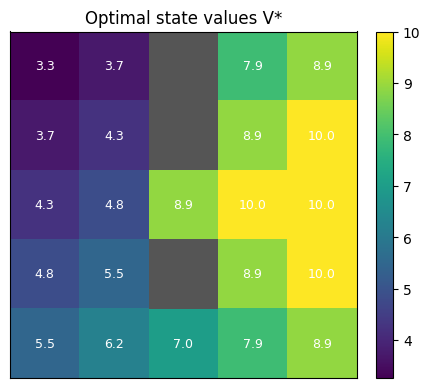

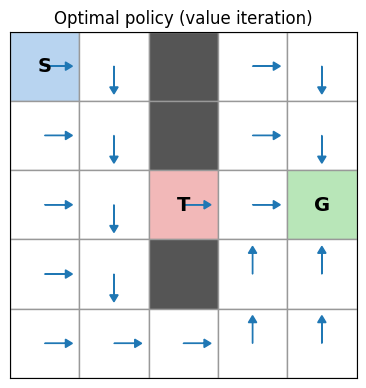

最优策略的路径： [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (3, 3), (2, 3), (2, 4)]
起点的价值 V*(S) = 3.262


In [6]:
V_star = value_iteration(env)
plot_values(V_star, 'Optimal state values V*')

pi_star = extract_policy(env, V_star)
plot_policy(pi_star, 'Optimal policy (value iteration)')

# 用贪心策略走一遍，检查它是否绕开了陷阱
s = env.reset()
traj = [s]
done = False
while not done and len(traj) <= 30:
    s, r, done, _, _ = env.step(pi_star[s])
    traj.append(s)
print('最优策略的路径：', [GridWorld.to_pos(x) for x in traj])
print('起点的价值 V*(S) =', round(V_star[GridWorld.to_state(GridWorld.START)], 3))

### 思考题 1

**1.1 把 γ 改成 0.5 和 0.99，最优策略会变吗？为什么？**

**1.2 如果环境会打滑（slip = 0.2，即 20% 的概率执行随机动作），
最优策略会发生什么变化？为什么？**

请用下面的单元格做实验，并在这里写下你的结论。

（你的答案）经过测试，发现gamma变动会改变最优策略。
而环境打滑，在当前设置下不会改变最优策略。

因为折扣系数变化会直接导致各个状态的当前价值和未来价值有改变，因此可以对最终训练得到的最佳路径产生改动。
而环境打滑改变的是状态转移的概率，在试错环节增加了随机性，但由于当前设置条件下最优路径有足够大的安全性，没有因为执行动作时不确定性的提高而改变当前的最佳选择。

In [7]:
# 提示：value_iteration 和 extract_policy 都接受 gamma 参数；
# 创建打滑环境用 GridWorld(slip=0.2, seed=0)。
# 思考题1.1：
print('折扣系数为：0.5:')
V_star = value_iteration(env, gamma = 0.5)
# plot_values(V_star, 'Optimal state values V*')

pi_star = extract_policy(env, V_star, gamma = 0.5)
# plot_policy(pi_star, 'Optimal policy (value iteration)')

# 用贪心策略走一遍，检查它是否绕开了陷阱
s = env.reset()
traj = [s]
done = False
while not done and len(traj) <= 30:
    s, r, done, _, _ = env.step(pi_star[s])
    traj.append(s)
print('最优策略的路径：', [GridWorld.to_pos(x) for x in traj])
print('起点的价值 V*(S) =', round(V_star[GridWorld.to_state(GridWorld.START)], 3))

print('折扣系数为：0.99:')
V_star = value_iteration(env, gamma = 0.99)
# plot_values(V_star, 'Optimal state values V*')

pi_star = extract_policy(env, V_star, gamma = 0.99)
# plot_policy(pi_star, 'Optimal policy (value iteration)')

# 用贪心策略走一遍，检查它是否绕开了陷阱
s = env.reset()
traj = [s]
done = False
while not done and len(traj) <= 30:
    s, r, done, _, _ = env.step(pi_star[s])
    traj.append(s)
print('最优策略的路径：', [GridWorld.to_pos(x) for x in traj])
print('起点的价值 V*(S) =', round(V_star[GridWorld.to_state(GridWorld.START)], 3))

# 思考题1.2：
print('环境打滑：slip == 0.2')
env.slip = 0.2
V_star = value_iteration(env)
# plot_values(V_star, 'Optimal state values V*')

pi_star = extract_policy(env, V_star)
# plot_policy(pi_star, 'Optimal policy (value iteration)')

# 用贪心策略走一遍，检查它是否绕开了陷阱
s = env.reset()
traj = [s]
done = False
while not done and len(traj) <= 30:
    s, r, done, _, _ = env.step(pi_star[s])
    traj.append(s)
print('最优策略的路径：', [GridWorld.to_pos(x) for x in traj])
print('起点的价值 V*(S) =', round(V_star[GridWorld.to_state(GridWorld.START)], 3))


折扣系数为：0.5:
最优策略的路径： [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (3, 3), (2, 3), (2, 4)]
起点的价值 V*(S) = -0.18
折扣系数为：0.99:
最优策略的路径： [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (3, 3), (2, 3), (2, 4)]
起点的价值 V*(S) = 8.27
环境打滑：slip == 0.2
最优策略的路径： [(0, 0), (0, 1), (1, 1), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (3, 3), (2, 3), (2, 4)]
起点的价值 V*(S) = 3.262


## Part 2：Q-learning（未知模型）

**知识回顾**

值迭代需要知道转移概率 P。现实中我们通常拿不到 P，只能和环境交互、试错。
时序差分（Temporal Difference，TD）方法直接从经验中学习：
每走一步，就用“目标值与当前估计的差”来修正估计。

Q-learning 的更新式是：

$$Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\right]$$

方括号里的部分叫做 TD 目标减当前估计，也就是 TD 误差。
请注意它和 Bellman 最优方程的关系：r + γ max Q(s′) 就是
“当前奖励 + 折扣后的未来价值”的采样版本。

探索策略使用 ε-greedy：以 ε 的概率随机选一个动作，否则选当前 Q 值最大的动作。

**你的任务**

1. 补全 `eps_greedy`。
2. 补全 `q_learning` 中的更新式。

提示：回合结束（done 为 True）时，未来价值按 0 计。

In [8]:
def eps_greedy(Q, s, epsilon, rng):
    import numpy as np
    # TODO 4：以 ε 的概率随机选一个动作，否则选 Q 值最大的动作。
    # 提示：rng.random() 生成 [0,1) 的随机数；
    # rng.integers(n) 生成 [0,n) 的随机整数。
    # 我的思路：
    # random_number = rng.random();
    # if random_number < epsilon:
    #   action_index = rng.integers(4);
    # else:
    #   action_index = np.argmax(Q[s]);
    # return action_index;
    random_number = rng.random();
    if random_number < epsilon:
        action = rng.integers(4);
    else:  
        action = np.argmax(Q[s]);
    return action;


def q_learning(env, episodes=3000, alpha=0.1, gamma=0.9,
               eps_start=0.3, eps_end=0.02, seed=0):
    import numpy as np
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, env.n_actions))
    returns = np.zeros(episodes)
    for ep in range(episodes):
        epsilon = eps_start + (eps_end - eps_start) * ep / episodes
        s = env.reset()
        total, done, truncated = 0.0, False, False
        while not (done or truncated):
            a = eps_greedy(Q, s, epsilon, rng)
            s_next, r, done, truncated, _ = env.step(a)
            # TODO 5：TD 更新。先算 TD 目标 r + γ·max Q(s′,·)，
            # 再按 Q(s,a) ← Q(s,a) + α·(目标 − Q(s,a)) 更新。
            # 提示：回合结束时未来价值按 0 计。
            # 我的思路：
            # if done == True:
            #     TD_target = r + 0;
            # else:
            #     TD_target = r + gamma * max(Q[s_next]);
            # Q[s][a] += alpha * (TD_target - Q[s][a]);
            if done == True:
                TD_target = r + 0;
            else:
                TD_target = r + gamma * np.max(Q[s_next]);
            Q[s][a] += alpha * (TD_target - Q[s][a]);
            s = s_next
            total += r
        returns[ep] = total
    return Q, returns

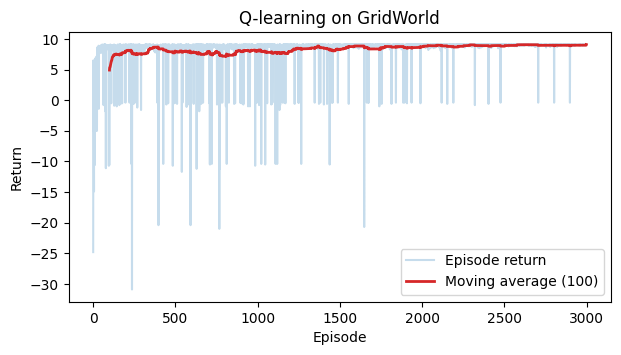

In [9]:
env2 = GridWorld(seed=1)
Q2, returns2 = q_learning(env2, episodes=3000, seed=1)
plot_returns(returns2, 'Q-learning on GridWorld')

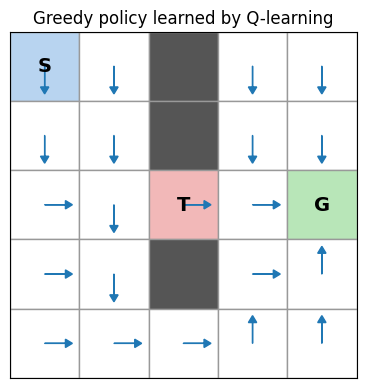

Q-learning 学到的路径： [(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (3, 3), (3, 4), (2, 4)]
该路径的真实回报 = 9.1


In [10]:
pi_q = np.argmax(Q2, axis=1)
plot_policy(pi_q, 'Greedy policy learned by Q-learning')

s = env2.reset()
traj_q, G_q, done = [s], 0.0, False
while not done and len(traj_q) <= 30:
    a = pi_q[s]
    s, r, done, _, _ = env2.step(a)
    traj_q.append(s)
    G_q += r
print('Q-learning 学到的路径：', [GridWorld.to_pos(x) for x in traj_q])
print('该路径的真实回报 =', round(G_q, 2))

**闭环验证**：Part 1 用值迭代（知道全部模型）算出的最优路径，
和 Part 2 用 Q-learning（只靠试错）学到的路径一致，都绕开了陷阱。
一个靠解方程，一个靠试错，殊途同归。

### 思考题 2

**2.1 SARSA 与 Q-learning 的更新式只差一处：
SARSA 用下一步实际执行的动作 a′ 计算目标，即 r + γ·Q(s′,a′)，
而不是 max Q(s′,·)。请实现 SARSA，并在本环境对比两者的策略。**

**2.2 调参练习：把 α 改成 0.01 和 0.5，把 ε 的起始值改成 0.05，
观察学习曲线的变化。**

请用下面的单元格做实验，并在这里写下你的结论。

（你的答案）经过测试，发现SARSA_learning学出来的是避开陷阱的策略，而Q_learning学出来的是贴边走的策略，可能的原因是SARSA是on-policy,采用下一步的结果作为目标，会考虑探索过程带来的风险，倾向于更安全的位置，而Q-learning是off-policy，是使用下一状态的最大Q值，假设下一步总能选择最优动作，因此可能倾向于学习更短的路径（尽管靠近陷阱）。当然奖励、探索策略等也会对两者的结果产生影响。

调参练习发现，alpha本来是0.1，变小为0.01后学习曲线收敛更慢了，变大为0.5后收敛更快，但是波动也更大，可以理解alpha为神经网络学习里面的学习率；
epsilon起始值本来是0.3，变成了0.05后曲线收敛速度似乎没有太大变化，但是后期更加平稳（波动小），原因可能是epsilon控制随机选择动作的概率，这个值越大那么智能体会更加多地随机试错，导致学习过程波动大；调小之后就倾向于稳定地选择Q值大的动作，确定性提升，学习曲线便平稳了。

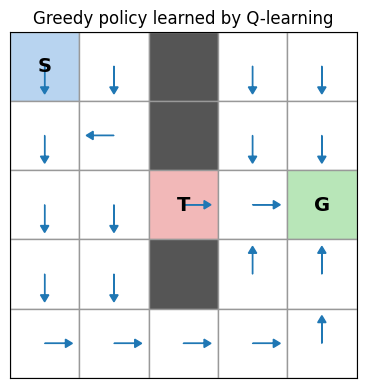

SARSA-learning 学到的路径： [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (3, 4), (2, 4)]
该路径的真实回报 = 9.1
q_learning 的 alpha 值为0.01：


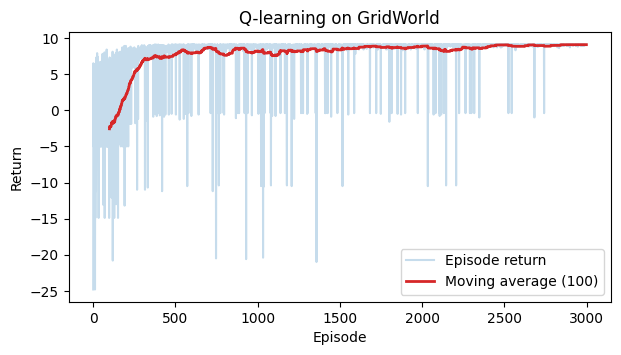

q_learning 的 alpha 值为0.5：


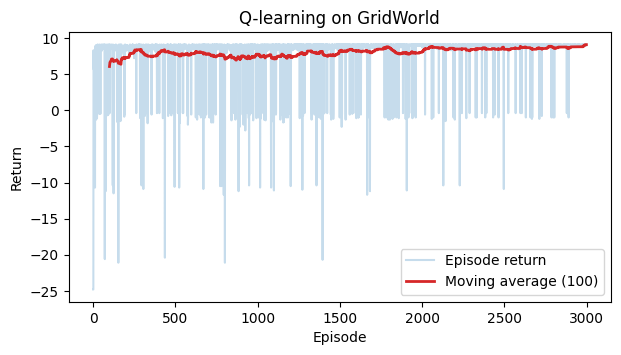

q_learning 的 epsilon 起始值为0.05：


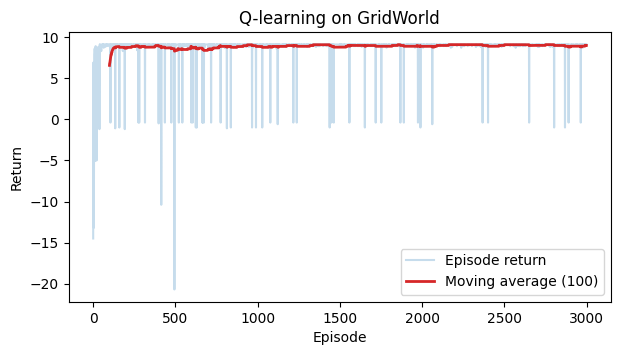

In [11]:
# 2.1 提示：把 q_learning 复制一份，改名 sarsa。
# 区别在于每步更新前，需要先用 eps_greedy 选出下一步实际执行的动作 a_next，
# 然后用 Q[s_next, a_next] 代替 np.max(Q[s_next])。
# 注意回合结束时不要再取 a_next 的价值。
# SARSA_LEARNING
def sarsa_learning(env, episodes=3000, alpha=0.1, gamma=0.9,
               eps_start=0.3, eps_end=0.02, seed=0):
    import numpy as np
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, env.n_actions))
    returns = np.zeros(episodes)
    for ep in range(episodes):
        epsilon = eps_start + (eps_end - eps_start) * ep / episodes
        s = env.reset()
        total, done, truncated = 0.0, False, False
        while not (done or truncated):
            a = eps_greedy(Q, s, epsilon, rng)
            s_next, r, done, truncated, _ = env.step(a)
            if done == True:
                TD_target = r + 0;
            else:
                a_next = eps_greedy(Q, s_next, epsilon, rng);
                TD_target = r + gamma * Q[s_next][a_next];
            Q[s][a] += alpha * (TD_target - Q[s][a]);
            s = s_next
            total += r
        returns[ep] = total
    return Q, returns
Q2, returns2 = sarsa_learning(env2, episodes=3000, seed=1)
pi_q = np.argmax(Q2, axis=1)
plot_policy(pi_q, 'Greedy policy learned by Q-learning')

s = env2.reset()
traj_q, G_q, done = [s], 0.0, False
while not done and len(traj_q) <= 30:
    a = pi_q[s]
    s, r, done, _, _ = env2.step(a)
    traj_q.append(s)
    G_q += r
print('SARSA-learning 学到的路径：', [GridWorld.to_pos(x) for x in traj_q])
print('该路径的真实回报 =', round(G_q, 2))

# 调参练习
print('q_learning 的 alpha 值为0.01：')
Q2, returns2 = q_learning(env2, episodes=3000, seed=1,alpha=0.01)
plot_returns(returns2, 'Q-learning on GridWorld')
print('q_learning 的 alpha 值为0.5：')
Q2, returns2 = q_learning(env2, episodes=3000, seed=1, alpha=0.5)
plot_returns(returns2, 'Q-learning on GridWorld')
print('q_learning 的 epsilon 起始值为0.05：')
Q2, returns2 = q_learning(env2, episodes=3000, seed=1, eps_start=0.05)
plot_returns(returns2, 'Q-learning on GridWorld')

## Part 3：Mini-RLHF（未知奖励）

**为什么需要这个部分**

Part 1 和 Part 2 都假设奖励函数是现成的。但很多真实任务里，
我们写不出奖励函数。例如“回答是否有帮助”“驾驶是否平稳”，
都无法用一行公式定义。

RLHF（Reinforcement Learning from Human Feedback，基于人类反馈的强化学习）
给出的方案是：让人类比较两段行为哪个更好，从偏好中学出一个奖励模型，
再用 RL 去优化这个学到的奖励。

| 真实 LLM 的 RLHF | 本实验 |
|---|---|
| 针对 prompt 生成多个回答 | 用行为策略采样多条轨迹 |
| 人工标注偏好 | 用隐藏的真实奖励自动标注 |
| 神经网络奖励模型 | 线性奖励模型（10 行 numpy） |
| PPO 优化 | Q-learning 优化 |

我们替换了策略优化器，但保留了 RLHF 最核心的结构：
从偏好学习奖励，再优化这个奖励。

**数学接口（请注意：这是教学简化）**

真实 LLM 的奖励模型看到的是“prompt + 完整回答”，输出一个标量分数，
并不会给每个 token 单独打分。本实验为了能继续复用 Q-learning，
把奖励模型设计成逐步可分解的形式：每一步打分，整条轨迹的分数是各步之和：

$$r_\theta(s,a,s') = \theta^\top \phi(s,a,s'), \qquad
R_\theta(\tau) = \sum_t r_\theta(s_t,a_t,s_{t+1})$$

偏好学习使用 Bradley-Terry 模型：轨迹 A 优于轨迹 B 的概率是

$$P(\tau_A \succ \tau_B) = \sigma\big(R_\theta(\tau_A) - R_\theta(\tau_B)\big)$$

虽然优化器不同、奖励分解被简化，但核心结构完全一致：
偏好 → 奖励模型 → 优化学到的奖励 →（下一节你会看到）reward hacking。
学出 θ 之后，把 r_θ 当作奖励，重新跑 Part 2 的 Q-learning。

### 3.1 特征：奖励模型能看到什么

奖励模型的特征只有三个：向终点靠近了多少、是否到达终点、步数。
**请注意：特征里没有“是否踩了陷阱”。**
这叫做表征盲区（representation misspecification）：
奖励模型从表示能力上就无法知道陷阱是坏事。

In [12]:
GOAL_POS = GridWorld.GOAL


def manhattan(pos):
    return abs(pos[0] - GOAL_POS[0]) + abs(pos[1] - GOAL_POS[1])


def phi(s, a, s_next):
    """单步特征：[到终点的距离变化, 是否到达终点, 步数指示]。"""
    p, p_next = GridWorld.to_pos(s), GridWorld.to_pos(s_next)
    import numpy as np
    return np.array([
        float(manhattan(p) - manhattan(p_next)),
        1.0 if p_next == GOAL_POS else 0.0,
        1.0,
    ])


def traj_features(steps):
    """整条轨迹的特征 = 各步特征之和。steps 是 (s, a, s_next) 的列表。"""
    import numpy as np
    return np.sum([phi(s, a, s2) for s, a, s2 in steps], axis=0)

### 3.2 收集偏好数据

我们用一个“中等水平的行为策略”生成轨迹：先取 Part 2 学好的 Q，
再以 10% 的概率随机动作。然后用隐藏的真实奖励给轨迹对标注偏好。

请注意一个关键细节：**凡是踩过陷阱的轨迹，都被从数据中剔除。**
这对应真实场景：标注员只会看到行为大致正常的样本，
灾难性的行为不在数据分布内。这叫做覆盖盲区（coverage gap）。

In [13]:
def collect_trajectories(env, Q_behavior, n_traj=200, noise=0.1,
                         max_steps=20, seed=0):
    """用带噪声的行为策略采样轨迹，并剔除踩过陷阱的轨迹（覆盖盲区）。"""
    import numpy as np
    rng = np.random.default_rng(seed)
    trap_s = GridWorld.to_state(GridWorld.TRAP)
    trajs = []
    while len(trajs) < n_traj:
        s = env.reset()
        steps, total, done = [], 0.0, False
        while not done and len(steps) < max_steps:
            a = eps_greedy(Q_behavior, s, noise, rng)
            s_next, r, done, _, _ = env.step(a)
            steps.append((s, a, s_next))
            s = s_next
            total += r
        if any(s2 == trap_s for _, _, s2 in steps):
            continue  # 覆盖盲区：标注数据不含灾难行为
        trajs.append((steps, total))
    return trajs


def make_preference_pairs(trajs, n_pairs=400, min_gap=0.5, seed=0):
    """随机配对，用真实回报标注哪条更好；差距太小的对子跳过。"""
    import numpy as np
    rng = np.random.default_rng(seed)
    pairs = []
    attempts = 0
    while len(pairs) < n_pairs and attempts < n_pairs * 50:
        attempts += 1
        i, j = rng.integers(len(trajs), size=2)
        if i == j:
            continue
        (steps_i, G_i), (steps_j, G_j) = trajs[i], trajs[j]
        if abs(G_i - G_j) < min_gap:
            continue
        winner, loser = (steps_i, steps_j) if G_i > G_j else (steps_j, steps_i)
        pairs.append((traj_features(winner), traj_features(loser)))
    return pairs

trajs = collect_trajectories(env2, Q2, seed=10)
pairs = make_preference_pairs(trajs, seed=11)
print(f'收集到 {len(trajs)} 条轨迹，{len(pairs)} 对偏好')

收集到 200 条轨迹，217 对偏好


### 3.3 训练奖励模型（Bradley-Terry）

损失函数是

$$L(\theta) = -\frac{1}{N}\sum_{\text{对子}} \log \sigma\left(\theta^\top(\Phi_w - \Phi_l)\right)$$

其中 Φ_w 和 Φ_l 分别是优胜轨迹和失败轨迹的特征和。
对单个对子，损失对 θ 的梯度是 $-\sigma(-\theta^\top(\Phi_w-\Phi_l)) \cdot (\Phi_w-\Phi_l)$。

**你的任务**：补全 `fit_reward_model` 中的梯度。
提示：sigmoid 函数已在下方定义。

In [14]:
def sigmoid(x):
    import numpy as np
    return 1.0 / (1.0 + np.exp(-x))


def fit_reward_model(pairs, lr=0.05, iters=3000, l2=1e-4):
    import numpy as np
    theta = np.zeros(3)
    for _ in range(iters):
        grad = np.zeros(3)
        for F_win, F_lose in pairs:
            diff = F_win - F_lose
            # TODO 6：累加单个对子的梯度 −σ(−θ·diff)·diff。
            # 提示：sigmoid 函数已在上方定义。
            # grad += -sigmoid(-theta * diff) * diff;
            grad += -sigmoid(-theta * diff) * diff;
        grad = grad / len(pairs) + l2 * theta
        theta -= lr * grad
    return theta

theta = fit_reward_model(pairs)
print('学到的奖励模型参数 θ =', np.round(theta, 3))
print('（三个分量依次对应：靠近终点、到达终点、步数）')


def r_hat(s, a, s_next, r):
    """用学到的奖励模型给每一步打分，替换环境的真实奖励。"""
    return float(theta @ phi(s, a, s_next))

学到的奖励模型参数 θ = [ 0.     0.    -1.634]
（三个分量依次对应：靠近终点、到达终点、步数）


### 3.4 用学到的奖励重新训练

现在把环境的真实奖励换成 r_θ，重新跑一遍 Part 2 的 Q-learning。
除了奖励的来源不同，其他代码完全一样。

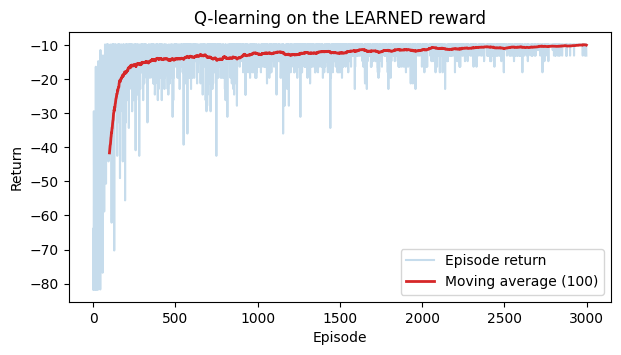

In [15]:
class RewardWrapper(GridWorld):
    """替换奖励函数的环境包装器。"""

    def __init__(self, reward_fn, **kwargs):
        self.reward_fn = reward_fn
        super().__init__(**kwargs)

    def step(self, a):
        s_old = self.to_state(self.pos)
        s_next, r, done, truncated, info = super().step(a)
        return s_next, self.reward_fn(s_old, a, s_next, r), done, truncated, info

env_rm = RewardWrapper(r_hat, seed=2)
Q_rlhf, returns_rlhf = q_learning(env_rm, episodes=3000, seed=2)
plot_returns(returns_rlhf, 'Q-learning on the LEARNED reward')

### 3.5 观察 Reward Hacking

现在我们有两个策略：在真实奖励上训练的基线策略，和在学到的奖励上训练的 RLHF 策略。
分别比较它们在两个口径下的表现：真实回报，以及奖励模型给出的分数。

基线策略：  奖励模型分数 = -16.34，真实回报 = 9.10
RLHF 策略： 奖励模型分数 = -9.81，真实回报 = -0.40


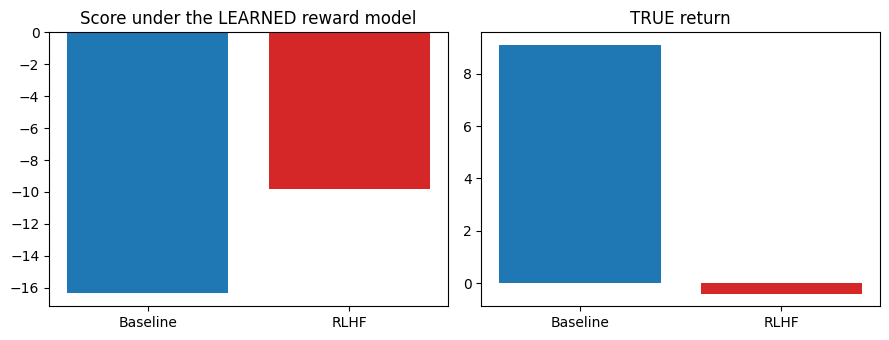

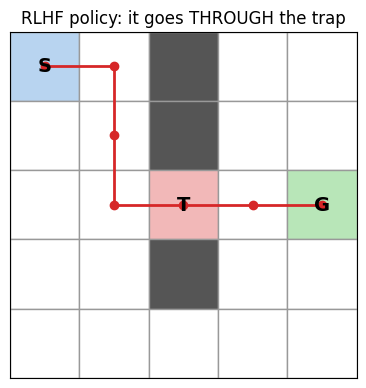

In [16]:
def greedy_traj(env, Q, max_steps=30):
    """按 Q 的贪心策略走一遍，返回 (s, a, s_next) 的列表。"""
    import numpy as np
    s = env.reset()
    steps, done = [], False
    while not done and len(steps) < max_steps:
        a = int(np.argmax(Q[s]))
        s_next, _, done, _, _ = env.step(a)
        steps.append((s, a, s_next))
        s = s_next
    return steps

env_eval = GridWorld(seed=3)
steps_base = greedy_traj(env_eval, Q2)
steps_rlhf = greedy_traj(env_eval, Q_rlhf)

true_base = sum(env_eval._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in steps_base)
true_rlhf = sum(env_eval._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in steps_rlhf)
proxy_base = sum(r_hat(s, a, s2, 0.0) for s, a, s2 in steps_base)
proxy_rlhf = sum(r_hat(s, a, s2, 0.0) for s, a, s2 in steps_rlhf)

print(f'基线策略：  奖励模型分数 = {proxy_base:.2f}，真实回报 = {true_base:.2f}')
print(f'RLHF 策略： 奖励模型分数 = {proxy_rlhf:.2f}，真实回报 = {true_rlhf:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].bar(['Baseline', 'RLHF'], [proxy_base, proxy_rlhf], color=['#1f77b4', '#d62728'])
axes[0].set_title('Score under the LEARNED reward model')
axes[1].bar(['Baseline', 'RLHF'], [true_base, true_rlhf], color=['#1f77b4', '#d62728'])
axes[1].set_title('TRUE return')
plt.tight_layout()
plt.show()

traj_rlhf_states = [steps_rlhf[0][0]] + [s2 for _, _, s2 in steps_rlhf]
plot_trajectory(traj_rlhf_states, 'RLHF policy: it goes THROUGH the trap')

**这就是 reward hacking。**

RLHF 策略在奖励模型上的分数比基线高了一大截，真实回报却从 9.1 跌到 -0.6。
它准确地优化了我们给它的目标，直接穿过陷阱抄近路。
优化器没有做错任何事，错的是奖励：

- 奖励模型看不到陷阱（表征盲区）。
- 训练数据里也没有踩陷阱的样本（覆盖盲区）。

于是“更短的路更好”这个在数据分布内成立的规律，
在陷阱面前失效了。这正是真实 RLHF 中每天都在发生的事情的缩微版。

In [17]:
# 稳健性检查（可选运行）：换 5 个种子重复整个流程，统计 hack 是否稳定出现
def mini_rlhf_once(seed):
    env_s = GridWorld(seed=seed)
    Q_b, _ = q_learning(env_s, episodes=3000, seed=seed)
    trajs_s = collect_trajectories(env_s, Q_b, seed=seed + 100)
    pairs_s = make_preference_pairs(trajs_s, seed=seed + 200)
    theta_s = fit_reward_model(pairs_s)
    env_m = RewardWrapper(lambda s, a, s2, r: float(theta_s @ phi(s, a, s2)), seed=seed)
    Q_m, _ = q_learning(env_m, episodes=3000, seed=seed + 300)
    env_e = GridWorld(seed=seed + 400)
    sb = greedy_traj(env_e, Q_b)
    sm = greedy_traj(env_e, Q_m)
    t_base = sum(env_e._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in sb)
    t_rlhf = sum(env_e._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in sm)
    trap_hit = any(s2 == GridWorld.to_state(GridWorld.TRAP) for _, _, s2 in sm)
    return t_base, t_rlhf, trap_hit


for sd in range(5):
    tb, tr, hit = mini_rlhf_once(sd)
    print(f'seed={sd}: 基线真实回报={tb:.2f}, RLHF 真实回报={tr:.2f}, 踩陷阱={hit}')

seed=0: 基线真实回报=9.10, RLHF 真实回报=-0.40, 踩陷阱=True
seed=1: 基线真实回报=9.10, RLHF 真实回报=-0.40, 踩陷阱=True
seed=2: 基线真实回报=9.10, RLHF 真实回报=-0.40, 踩陷阱=True
seed=3: 基线真实回报=9.10, RLHF 真实回报=-0.40, 踩陷阱=True
seed=4: 基线真实回报=9.10, RLHF 真实回报=-0.40, 踩陷阱=True


### 思考题 3

**3.1 如果给特征加上“是否踩陷阱”一项，reward hacking 会消失吗？请验证。**

**3.2 覆盖盲区如果不存在，hack 还会发生吗？**

**3.3 举一个真实 AI 系统中 reward hacking 的例子。**

请用下面的单元格做实验，并在这里写下你的结论。

（你的答案）经过下面的验证，发现加上“是否踩陷阱”的特征后，reward hacking不会消失，因为数据里并没有关于踩到陷阱的例子，所以奖励模型实际上仍然没有判别“是否踩陷阱比较好”的能力；

如果加入少量的含有踩陷阱的轨迹的数据，则reward hacking会消失。
另外注意到加入的含有踩陷阱的轨迹的数据如果不是少量而是很多（下面步骤3中添加了5条这类轨迹），则训练轨迹无法得到正常到达终点的结果。为什么会这样，我通过和AI讨论，发现主要是数据失衡的问题：在这种情况下，实际上模型见到的数据里很大部分是有踩陷阱的轨迹，而这类轨迹的奖励很低，而模型接触到的正常走到终点的轨迹数据变少了，所以很可能模型学不到正确的路径，而是倾向于学会采用保守策略来减少犯错的可能性。

真实系统中reward hacking可以参考之前早期GPT对数值比较的幻觉：9.1 < 9.09；这个现象当然是多方面的，但一个原因可能是在RLHF训练时人类标注师或者奖励模型几乎接触到的数据存在失衡问题（覆盖盲区），或者评价机制存在不足（缺失了“数字比较的特征”），比如很多都是直接对最终回答的文本风格好坏进行评价，而精确的数字比较没有被纳入评价范畴或者这类数据很少，导致LLM的输出可能语言流畅但是数值上错误也一样可以获得高奖励，从而无法学会数字比较。



步骤1：不含踩陷阱轨迹的偏好数据，但是奖励模型有“到达陷阱”分量
收集到 200 条轨迹，217 对偏好
学到的奖励模型参数 θ = [ 0.     0.    -1.634  0.   ]
（四个分量依次对应：靠近终点、到达终点、步数、到达陷阱）
基线策略：  奖励模型分数 = -16.34，真实回报 = 9.10
RLHF 策略： 奖励模型分数 = -9.81，真实回报 = -0.40


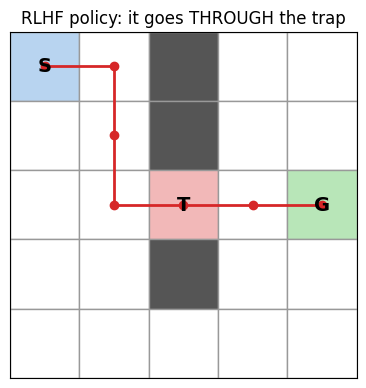

步骤2：保留少量踩陷阱轨迹的偏好数据，奖励模型仍有“到达陷阱”分量
收集到 200 条轨迹，400 对偏好
学到的奖励模型参数 θ = [ 0.     0.    -0.036 -4.693]
（四个分量依次对应：靠近终点、到达终点、步数、到达陷阱）
基线策略：  奖励模型分数 = -0.36，真实回报 = 9.10
RLHF 策略： 奖励模型分数 = -0.36，真实回报 = 9.10


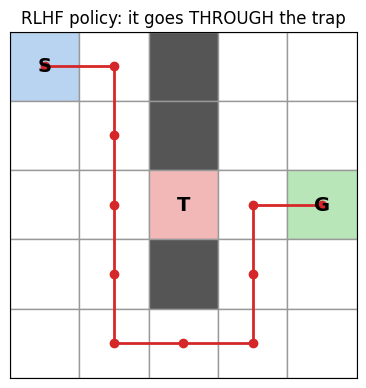

步骤3：保留很多踩陷阱轨迹的偏好数据，奖励模型仍有“到达陷阱”分量
收集到 200 条轨迹，400 对偏好
学到的奖励模型参数 θ = [ 0.     0.     0.051 -4.759]
（四个分量依次对应：靠近终点、到达终点、步数、到达陷阱）


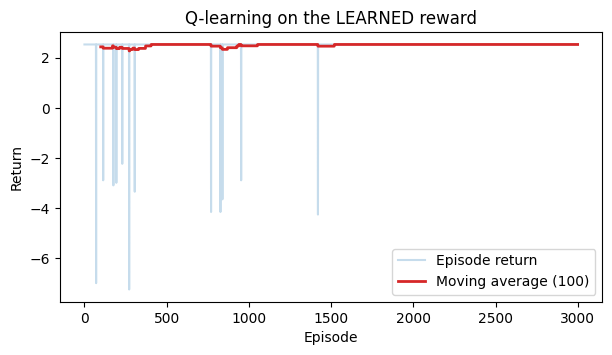

基线策略：  奖励模型分数 = 0.51，真实回报 = 9.10
RLHF 策略： 奖励模型分数 = 1.52，真实回报 = -3.00


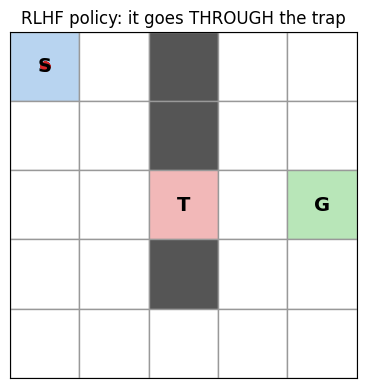

In [18]:
# 3.1 提示：分两步验证，结论可能和直觉不同。
# 第一步：给 phi 追加一个“下一状态是否是陷阱”的分量，
# 用同样的偏好数据（仍不含踩陷阱的轨迹）重新训练奖励模型，
# 观察 RLHF 策略是否改变。
# 第二步：让偏好数据保留少量踩陷阱的轨迹，重新训练，再观察。
# 你可以复用上面的 collect_trajectories、make_preference_pairs
# 和 RewardWrapper，只需要自己写带 4 个分量的特征函数。
TRAP_POS = GridWorld.TRAP
def phi(s, a, s_next):
    """单步特征：[到终点的距离变化, 是否到达终点, 步数指示, 是否到达陷阱]。"""
    p, p_next = GridWorld.to_pos(s), GridWorld.to_pos(s_next)
    import numpy as np
    return np.array([
        float(manhattan(p) - manhattan(p_next)),
        1.0 if p_next == GOAL_POS else 0.0,
        1.0,
        1.0 if p_next == TRAP_POS else 0.0,
    ])


# #修改theta张量长度
def fit_reward_model2(pairs, lr=0.05, iters=3000, l2=1e-4):
    import numpy as np
    theta = np.zeros(4)
    for _ in range(iters):
        grad = np.zeros(4)
        for F_win, F_lose in pairs:
            diff = F_win - F_lose
            # TODO 6：累加单个对子的梯度 −σ(−θ·diff)·diff。
            # 提示：sigmoid 函数已在上方定义。
            # grad += -sigmoid(-theta * diff) * diff;
            grad += -sigmoid(-theta * diff) * diff;
        grad = grad / len(pairs) + l2 * theta
        theta -= lr * grad
    return theta
print('步骤1：不含踩陷阱轨迹的偏好数据，但是奖励模型有“到达陷阱”分量')
trajs = collect_trajectories(env2, Q2, seed=10)
pairs = make_preference_pairs(trajs, seed=11)
print(f'收集到 {len(trajs)} 条轨迹，{len(pairs)} 对偏好')

theta = fit_reward_model2(pairs)
print('学到的奖励模型参数 θ =', np.round(theta, 3))
print('（四个分量依次对应：靠近终点、到达终点、步数、到达陷阱）')

env_rm = RewardWrapper(r_hat, seed=2)
Q_rlhf, returns_rlhf = q_learning(env_rm, episodes=3000, seed=2)
# plot_returns(returns_rlhf, 'Q-learning on the LEARNED reward')

env_eval = GridWorld(seed=3)
steps_base = greedy_traj(env_eval, Q2)
steps_rlhf = greedy_traj(env_eval, Q_rlhf)

true_base = sum(env_eval._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in steps_base)
true_rlhf = sum(env_eval._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in steps_rlhf)
proxy_base = sum(r_hat(s, a, s2, 0.0) for s, a, s2 in steps_base)
proxy_rlhf = sum(r_hat(s, a, s2, 0.0) for s, a, s2 in steps_rlhf)

print(f'基线策略：  奖励模型分数 = {proxy_base:.2f}，真实回报 = {true_base:.2f}')
print(f'RLHF 策略： 奖励模型分数 = {proxy_rlhf:.2f}，真实回报 = {true_rlhf:.2f}')

# fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
# axes[0].bar(['Baseline', 'RLHF'], [proxy_base, proxy_rlhf], color=['#1f77b4', '#d62728'])
# axes[0].set_title('Score under the LEARNED reward model')
# axes[1].bar(['Baseline', 'RLHF'], [true_base, true_rlhf], color=['#1f77b4', '#d62728'])
# axes[1].set_title('TRUE return')
# plt.tight_layout()
# plt.show()

traj_rlhf_states = [steps_rlhf[0][0]] + [s2 for _, _, s2 in steps_rlhf]
plot_trajectory(traj_rlhf_states, 'RLHF policy: it goes THROUGH the trap')

print('步骤2：保留少量踩陷阱轨迹的偏好数据，奖励模型仍有“到达陷阱”分量')
def collect_trajectories2(env, Q_behavior, n_traj=200, noise=0.1,
                         max_steps=20, seed=0):
    """用带噪声的行为策略采样轨迹，并剔除踩过陷阱的轨迹（覆盖盲区）。"""
    import numpy as np
    count = 0
    rng = np.random.default_rng(seed)
    trap_s = GridWorld.to_state(GridWorld.TRAP)
    trajs = []
    while len(trajs) < n_traj:
        s = env.reset()
        steps, total, done = [], 0.0, False
        while not done and len(steps) < max_steps:
            a = eps_greedy(Q_behavior, s, noise, rng)
            s_next, r, done, _, _ = env.step(a)
            steps.append((s, a, s_next))
            s = s_next
            total += r
        if any(s2 == trap_s for _, _, s2 in steps) :
            if count >= 4:  #
                continue  # 覆盖盲区：标注数据不含灾难行为
            else:
                count += 1;
        trajs.append((steps, total))
    return trajs

trajs = collect_trajectories2(env2, Q2, seed=10)
pairs = make_preference_pairs(trajs, seed=11)
print(f'收集到 {len(trajs)} 条轨迹，{len(pairs)} 对偏好')

theta = fit_reward_model2(pairs)
print('学到的奖励模型参数 θ =', np.round(theta, 3))
print('（四个分量依次对应：靠近终点、到达终点、步数、到达陷阱）')

env_rm = RewardWrapper(r_hat, seed=2)
Q_rlhf, returns_rlhf = q_learning(env_rm, episodes=3000, seed=2)
# plot_returns(returns_rlhf, 'Q-learning on the LEARNED reward')

env_eval = GridWorld(seed=3)
steps_base = greedy_traj(env_eval, Q2)
steps_rlhf = greedy_traj(env_eval, Q_rlhf)

true_base = sum(env_eval._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in steps_base)
true_rlhf = sum(env_eval._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in steps_rlhf)
proxy_base = sum(r_hat(s, a, s2, 0.0) for s, a, s2 in steps_base)
proxy_rlhf = sum(r_hat(s, a, s2, 0.0) for s, a, s2 in steps_rlhf)

print(f'基线策略：  奖励模型分数 = {proxy_base:.2f}，真实回报 = {true_base:.2f}')
print(f'RLHF 策略： 奖励模型分数 = {proxy_rlhf:.2f}，真实回报 = {true_rlhf:.2f}')

# fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
# axes[0].bar(['Baseline', 'RLHF'], [proxy_base, proxy_rlhf], color=['#1f77b4', '#d62728'])
# axes[0].set_title('Score under the LEARNED reward model')
# axes[1].bar(['Baseline', 'RLHF'], [true_base, true_rlhf], color=['#1f77b4', '#d62728'])
# axes[1].set_title('TRUE return')
# plt.tight_layout()
# plt.show()

traj_rlhf_states = [steps_rlhf[0][0]] + [s2 for _, _, s2 in steps_rlhf]
plot_trajectory(traj_rlhf_states, 'RLHF policy: it goes THROUGH the trap')

print('步骤3：保留很多踩陷阱轨迹的偏好数据，奖励模型仍有“到达陷阱”分量')
def collect_trajectories3(env, Q_behavior, n_traj=200, noise=0.1,
                         max_steps=20, seed=0):
    """用带噪声的行为策略采样轨迹，并剔除踩过陷阱的轨迹（覆盖盲区）。"""
    import numpy as np
    count = 0
    rng = np.random.default_rng(seed)
    trap_s = GridWorld.to_state(GridWorld.TRAP)
    trajs = []
    while len(trajs) < n_traj:
        s = env.reset()
        steps, total, done = [], 0.0, False
        while not done and len(steps) < max_steps:
            a = eps_greedy(Q_behavior, s, noise, rng)
            s_next, r, done, _, _ = env.step(a)
            steps.append((s, a, s_next))
            s = s_next
            total += r
        if any(s2 == trap_s for _, _, s2 in steps):
            if count >= 5:  #
                continue  # 覆盖盲区：标注数据不含灾难行为
            else:
                count += 1;
        trajs.append((steps, total))
    return trajs


trajs = collect_trajectories3(env2, Q2, seed=10)
pairs = make_preference_pairs(trajs, seed=11)
print(f'收集到 {len(trajs)} 条轨迹，{len(pairs)} 对偏好')

theta = fit_reward_model2(pairs)
print('学到的奖励模型参数 θ =', np.round(theta, 3))
print('（四个分量依次对应：靠近终点、到达终点、步数、到达陷阱）')

env_rm = RewardWrapper(r_hat, seed=2)
Q_rlhf, returns_rlhf = q_learning(env_rm, episodes=3000, seed=2)
plot_returns(returns_rlhf, 'Q-learning on the LEARNED reward')

env_eval = GridWorld(seed=3)
steps_base = greedy_traj(env_eval, Q2)
steps_rlhf = greedy_traj(env_eval, Q_rlhf)

true_base = sum(env_eval._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in steps_base)
true_rlhf = sum(env_eval._outcome(GridWorld.to_pos(s), a)[1] for s, a, s2 in steps_rlhf)
proxy_base = sum(r_hat(s, a, s2, 0.0) for s, a, s2 in steps_base)
proxy_rlhf = sum(r_hat(s, a, s2, 0.0) for s, a, s2 in steps_rlhf)

print(f'基线策略：  奖励模型分数 = {proxy_base:.2f}，真实回报 = {true_base:.2f}')
print(f'RLHF 策略： 奖励模型分数 = {proxy_rlhf:.2f}，真实回报 = {true_rlhf:.2f}')

# fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
# axes[0].bar(['Baseline', 'RLHF'], [proxy_base, proxy_rlhf], color=['#1f77b4', '#d62728'])
# axes[0].set_title('Score under the LEARNED reward model')
# axes[1].bar(['Baseline', 'RLHF'], [true_base, true_rlhf], color=['#1f77b4', '#d62728'])
# axes[1].set_title('TRUE return')
# plt.tight_layout()
# plt.show()

traj_rlhf_states = [steps_rlhf[0][0]] + [s2 for _, _, s2 in steps_rlhf]
plot_trajectory(traj_rlhf_states, 'RLHF policy: it goes THROUGH the trap')

## Part 4：从 learned reward 到 verifiable reward

**知识回顾**

Part 3 的问题出在奖励是“学出来的”：learned reward model 是真实目标的一层近似，
近似就会有误差，误差就会被优化器利用。但有些任务的成败可以直接用程序判定：

- 数学：最终答案是否等于标准答案。
- 代码：单元测试是否通过。
- 本实验的格子世界：是否到达终点、是否踩了陷阱。

两条路线的差别在于：

```text
learned reward：   true objective → learned reward model → policy
                   （多了一层近似，可能学错）
verifiable reward：task specification → explicit verifier → policy
                   （去掉了 learned reward model 这一层近似）
```

用程序化验证器（verifier）给出的判定作为奖励，
就是 RLVR（Reinforcement Learning with Verifiable Rewards）的基本思想。
请注意结论的分寸：RLVR 去掉了“奖励模型学错”这一类问题，
但 verifier 自身仍然可能定义不完整、覆盖不足、被 exploit、与真实目标不一致。

**你的任务**：把奖励换成 verifier 的输出，重新训练 Q-learning。

提示：补全 `verifier`。到达终点返回 +1，踩陷阱返回 -1，
其余情况返回 -0.01（时间成本）。
用 GridWorld.to_pos(s_next) 得到位置，与 GridWorld.GOAL、GridWorld.TRAP 比较。

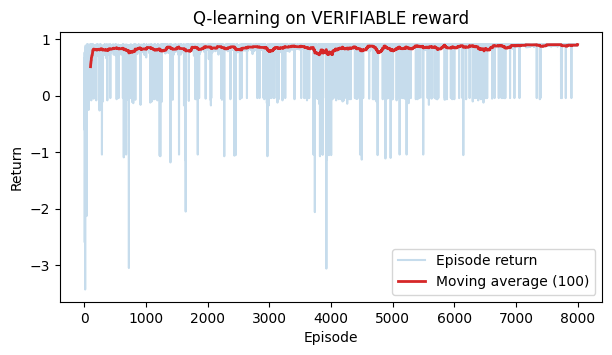

verifiable reward 训练出的路径： [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (3, 3), (3, 4), (2, 4)]
经过陷阱？ False


In [19]:
def verifier(s, a, s_next, r):
    # TODO 7：可验证奖励。到达终点返回 +1，踩陷阱返回 -1，
    # 其余情况返回 -0.01（时间成本）。
    # 提示：用 GridWorld.to_pos(s_next) 得到位置，与
    # GridWorld.GOAL、GridWorld.TRAP 比较。
    # 我的思路：
    # p_next = GridWorld.to_pos(s_next)
    # if s_next == GridWorld.GOAL:
    #   return 1.0
    # elif s_next == GridWorld.TRAP:
    #   return -1.0
    # else:
    #   return -0.01
    p_next = GridWorld.to_pos(s_next)
    if p_next == GridWorld.GOAL:
        return 1.0
    elif p_next == GridWorld.TRAP:
        return -1.0
    else:
        return -0.01


env_v = RewardWrapper(verifier, max_steps=60, seed=4)
Q_v, returns_v = q_learning(env_v, episodes=8000, eps_start=0.4, seed=4)
plot_returns(returns_v, 'Q-learning on VERIFIABLE reward')

steps_v = greedy_traj(GridWorld(seed=5), Q_v)
traj_v = [steps_v[0][0]] + [s2 for _, _, s2 in steps_v]
print('verifiable reward 训练出的路径：', [GridWorld.to_pos(x) for x in traj_v])
print('经过陷阱？', GridWorld.to_state(GridWorld.TRAP) in traj_v)

与 Part 3 对比：这次策略回到了绕远路。
到达终点和踩陷阱都由明确的规则判定，
中间没有 learned reward model 这层近似可以被利用。

### 4.1 但是：verifier 设计错了，hack 会立刻回来

下面的 verifier 只检查“是否到达终点”，不检查陷阱。
这相当于代码任务里只跑公开测试用例。请观察会发生什么。

In [20]:
def verifier_goal_only(s, a, s_next, r):
    """有漏洞的 verifier：只查到达终点，不查陷阱。"""
    if GridWorld.to_pos(s_next) == GridWorld.GOAL:
        return 1.0
    return -0.01

env_g = RewardWrapper(verifier_goal_only, max_steps=60, seed=4)
Q_g, _ = q_learning(env_g, episodes=8000, eps_start=0.4, seed=4)
steps_g = greedy_traj(GridWorld(seed=5), Q_g)
traj_g = [steps_g[0][0]] + [s2 for _, _, s2 in steps_g]
print('goal-only verifier 训练出的路径：', [GridWorld.to_pos(x) for x in traj_g])
print('经过陷阱？', GridWorld.to_state(GridWorld.TRAP) in traj_g)

goal-only verifier 训练出的路径： [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2), (2, 3), (2, 4)]
经过陷阱？ True


只查终点的 verifier 让穿陷阱的近路再次成为最优：
6 步拿到 +1，比绕 10 步的折现价值更高。
测试全部通过，隐患却一路畅通。这正是代码模型硬编码测试用例的格子世界版。

**本部分的完整结论**：

- learned reward 可以被 exploit，因为它是真实目标的一层近似（Part 3）。
- verifiable reward 去掉了 learned reward model 这层近似（Part 4）。
- 但 verifier 本身定义了什么是“对”，定义错了照样被 exploit（4.1 节）。
- 目标定义问题不会消失，只是转移了位置。这就是对齐（alignment）难的原因。

### 思考题 4

**4.1 为什么数学和代码适合 RLVR，而“回答是否有帮助”不适合？**

**4.2 既然 RLVR 有这么多优点，为什么 ChatGPT 仍然需要 RLHF？**

请在这里写下你的答案（本题为文字题，不需要代码）。

（你的答案）我的直观理解是数学和代码有明确、可自动验证的评判机制（例如数学的等式，代码编译通过），不需要借助主观的评价进行模糊性打分；相比之下，如果采用“回答是否有帮助”的机制来评价往往具有主观性和情景依赖，可能奖励一些看上去挺合理但完全不正确的结果，这样训练得到的模型是不合格的。

RLVR和RLHF适合不同的场景，数学和代码任务的正确性判别于RLVR很适合，但还有一些问题如代码可读性、步骤简洁程度等方面无法进行自动化判别；除此之外很多领域（例如医学诊断，文本流畅程度评价）既不存在严格的客观的评价标准，也不适合进行绝对化的评价（例如完全否认某种疾病），在这类场景中常常需要借助人类的主观评价进行标注，帮助模型生成符合人类认知的答案（可能有瑕疵，但是能接受）。因此实际训练时需要RLVR和RHLF结合使用，前者增强可验证任务的正确性，后者优化难以形式化的人类偏好。

## 拓展探索（不计分）

**用 PPO 训练一个连续控制智能体**

本实验的 Q-learning 处理的是离散状态、离散动作的小问题。
面对连续状态或连续动作，需要函数近似和策略梯度方法。
把下面的代码粘贴到 Colab 中运行（CPU 约 3 分钟），
可以训练一个 PPO 智能体平衡倒立摆（Pendulum，连续动作空间）：

```python
!pip install stable-baselines3
import gymnasium as gym
from stable_baselines3 import PPO

env = gym.make('Pendulum-v1')
model = PPO('MlpPolicy', env, verbose=1, seed=0)
model.learn(total_timesteps=30000)
```

**进一步阅读**

- Sutton & Barto《Reinforcement Learning: An Introduction》第 3、4、6 章。
- DeepSeek-R1 论文（Nature, 2025），重点看奖励设计一节。
- OpenAI 博客《Faulty Reward Functions in the Wild》，赛艇游戏的原始案例。

## 拓展：PPO 与 DPO 的教学版实现

前面的 Mini-RLHF 已经完成了“偏好 → 奖励模型 → 策略优化”的完整流程。
这里补充两种真实 LLM 后训练中常见的方法：PPO 和 DPO。

### 5.1 PPO：用奖励直接更新策略，但不要一步走太远

PPO（Proximal Policy Optimization）属于在线强化学习。它反复执行四步：

1. 用当前策略采样若干条轨迹；
2. 根据奖励计算每个动作的回报和优势（advantage）；
3. 提高优势为正的动作概率，降低优势为负的动作概率；
4. 用 clip 限制新旧策略的概率比，避免一次更新过大。

如果旧策略选择某动作的概率是 `p_old`，新策略的概率是 `p_new`，PPO 关注：

$$r_t(\theta)=\frac{p_{new}}{p_{old}}$$

当优势为正时，我们希望提高该动作的概率；当优势为负时，我们希望降低它。
如果概率比超过 `1 + clip_eps` 或低于 `1 - clip_eps`，就停止继续放大这次更新。
这就是 PPO 名称中“近端（proximal）”的含义。

本 notebook 使用表格策略而不是神经网络：每个状态有 4 个 action logits，
softmax 把 logits 转成动作概率；价值函数也只是每个状态一个数。
因此代码短，适合观察 PPO 的数据流，但不代表真实 LLM 的 token 级 PPO。

### 5.2 DPO：不再单独训练奖励模型，直接学习偏好

DPO（Direct Preference Optimization）使用离线偏好对：

- `chosen`：偏好的回答或轨迹；
- `rejected`：不偏好的回答或轨迹。

它同时保留一个冻结的参考策略 `π_ref`，用来表示“不要偏离原模型太远”。
核心思想不是只提高 chosen 的概率，而是提高 chosen 相对于 rejected 的概率，
并比较这种差异是否超过参考策略。

损失可以写成 `-log(sigmoid(x))`。如果模型还没有充分偏向 chosen，
梯度会推动它增加 chosen、减少 rejected；如果已经偏得足够多，更新会逐渐变小。

与 PPO 对比：PPO 需要当前策略在线采样并计算奖励；DPO 直接使用已有偏好数据，
因此实现和训练流程更简单，但它无法自动纠正偏好数据中的错误。


PPO mean return over last 40 episodes = 9.09
PPO greedy-policy true return = 9.1


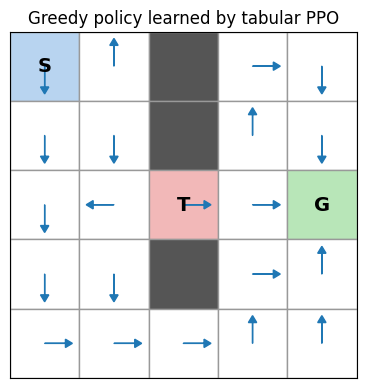

In [25]:
def _softmax_rows(logits):
    z = logits - np.max(logits, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


def _sample_action(probs, state, rng):
    return int(rng.choice(len(probs[state]), p=probs[state]))


def ppo_learning(env, updates=400, episodes_per_update=16, gamma=0.99,
                 clip_eps=0.2, policy_lr=0.02, value_lr=0.05,
                 update_epochs=4, seed=0):

    rng = np.random.default_rng(seed)
    logits = np.zeros((env.n_states, env.n_actions))
    values = np.zeros(env.n_states)
    returns = []

    for update in range(updates):
        batch = []
        for _ in range(episodes_per_update):
            s = env.reset()
            episode = []
            done = truncated = False
            while not (done or truncated):
                probs = _softmax_rows(logits)
                a = _sample_action(probs, s, rng)
                s_next, r, done, truncated, _ = env.step(a)
                old_logp = np.log(max(probs[s, a], 1e-12))
                episode.append((s, a, r, s_next, done or truncated, old_logp))
                s = s_next

            G = 0.0
            for s, a, r, s_next, terminal, old_logp in reversed(episode):
                G = r + (0.0 if terminal else gamma * G)
                advantage = G - values[s]
                batch.append((s, a, G, advantage, old_logp))
            returns.append(sum(item[2] for item in episode))

        for _ in range(update_epochs):
            probs = _softmax_rows(logits)
            for s, a, target, advantage, old_logp in batch:
                current_logp = np.log(max(probs[s, a], 1e-12))
                ratio = np.exp(np.clip(current_logp - old_logp, -20.0, 20.0))
                clipped = np.clip(ratio, 1.0 - clip_eps, 1.0 + clip_eps)
                use_ratio = not (advantage >= 0 and ratio > clipped or
                                 advantage < 0 and ratio < clipped)
                if use_ratio:
                    grad = advantage * ratio * (np.eye(env.n_actions)[a] - probs[s])
                    logits[s] += policy_lr * grad
                values[s] += value_lr * (target - values[s])
                probs = _softmax_rows(logits)
    return logits, values, np.asarray(returns)


ppo_logits, ppo_values, ppo_returns = ppo_learning(GridWorld(seed=20), seed=20)
pi_ppo = np.argmax(ppo_logits, axis=1)
steps_ppo = greedy_traj(GridWorld(seed=21), np.exp(ppo_logits))
eval_env = GridWorld(seed=21)
ppo_true = sum(eval_env._outcome(GridWorld.to_pos(s), a)[1]
               for s, a, _ in steps_ppo)
print('PPO mean return over last 40 episodes =', round(float(np.mean(ppo_returns[-40:])), 2))
print('PPO greedy-policy true return =', round(ppo_true, 2))
plot_policy(pi_ppo, 'Greedy policy learned by tabular PPO')


DPO number of preference pairs = 248
DPO greedy-policy true return = -3.0


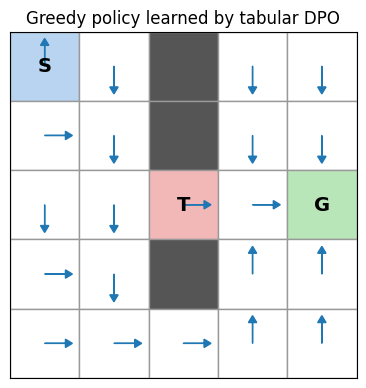

In [23]:
def collect_dpo_pairs(env, Q_behavior, n_pairs=300, noise=0.2,
                      max_steps=20, seed=0):

    rng = np.random.default_rng(seed)
    trajectories = []
    while len(trajectories) < n_pairs * 3:
        s = env.reset()
        steps, total = [], 0.0
        done = truncated = False
        while not (done or truncated) and len(steps) < max_steps:
            a = eps_greedy(Q_behavior, s, noise, rng)
            s_next, r, done, truncated, _ = env.step(a)
            steps.append((s, a, s_next))
            total += r
            s = s_next
        trajectories.append((steps, total))

    pairs = []
    for _ in range(n_pairs):
        i, j = rng.integers(len(trajectories), size=2)
        if i == j or trajectories[i][1] == trajectories[j][1]:
            continue
        first, second = trajectories[i], trajectories[j]
        pairs.append((first[0], second[0]) if first[1] > second[1]
                     else (second[0], first[0]))
    return pairs


def _sequence_log_prob(logits, steps):
    probs = _softmax_rows(logits)
    return sum(np.log(max(probs[s, a], 1e-12)) for s, a, _ in steps)


def dpo_learning(preference_pairs, reference_logits, beta=0.5,
                 lr=0.03, epochs=20):

    logits = reference_logits.copy()
    for _ in range(epochs):
        for chosen, rejected in preference_pairs:
            ref_gap = (_sequence_log_prob(reference_logits, chosen)
                       - _sequence_log_prob(reference_logits, rejected))
            policy_gap = (_sequence_log_prob(logits, chosen)
                         - _sequence_log_prob(logits, rejected))
            x = beta * (policy_gap - ref_gap)
            coeff = 1.0 / (1.0 + np.exp(np.clip(x, -40.0, 40.0))) - 1.0
            probs = _softmax_rows(logits)
            for s, a, _ in chosen:
                logits[s] -= lr * beta * coeff * (np.eye(logits.shape[1])[a] - probs[s])
            for s, a, _ in rejected:
                logits[s] += lr * beta * coeff * (np.eye(logits.shape[1])[a] - probs[s])
    return logits


dpo_pairs = collect_dpo_pairs(GridWorld(seed=30), Q2, seed=30)
dpo_logits = dpo_learning(dpo_pairs, Q2)
pi_dpo = np.argmax(dpo_logits, axis=1)
steps_dpo = greedy_traj(GridWorld(seed=31), np.exp(dpo_logits))
eval_env = GridWorld(seed=31)
dpo_true = sum(eval_env._outcome(GridWorld.to_pos(s), a)[1]
               for s, a, _ in steps_dpo)
print('DPO number of preference pairs =', len(dpo_pairs))
print('DPO greedy-policy true return =', round(dpo_true, 2))
plot_policy(pi_dpo, 'Greedy policy learned by tabular DPO')
